# Практика 4

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt


def showpic(image, title, cmap='gray'):
    plt.figure()
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.show()

def homo_average(img, mask, point, T):
    masked_pixels = img[mask > 0]
    if masked_pixels.size == 0:
        return False
    av_val = masked_pixels.sum() / np.count_nonzero(masked_pixels)

    if abs(av_val - img[point]) <= T:
        return True
    return False

def homo_std_dev(img, mask, point, T):
    masked_pixels = img[mask > 0]
    T_min = 15.0

    if masked_pixels.size < 5:
        return abs(masked_pixels.mean() - img[point]) <= T_min

    av_val = masked_pixels.mean()
    std_val = max(masked_pixels.std(), 1.0)
    return abs(av_val - img[point]) <= max(T * std_val, T_min)

def region_growing(image, seed_point, homo_fun, r, T, verbose=False):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    iterations = 0
    while count > 0:
        count = 0
        local_mask = np.zeros(image.shape, np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i, j] == 0 and mask[i - r:i + r, j - r:j + r].sum() > 0:
                    if homo_fun(image, mask, (i, j), T):
                        local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        mask += local_mask
        iterations += 1
        if verbose:
            print(f"Iteration {iterations}: added {count} px")
        if iterations > 10000:
            print("Limit, break")
            break

    return mask * 255


# Задание 1

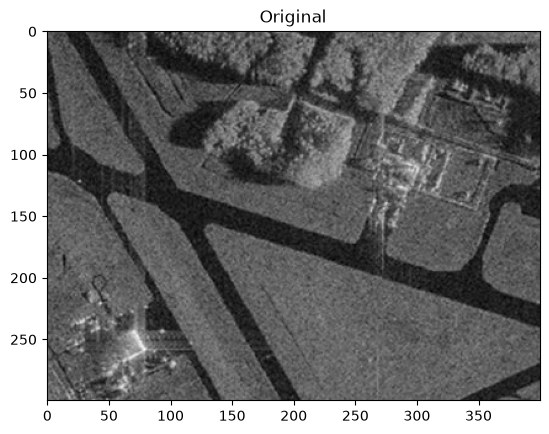

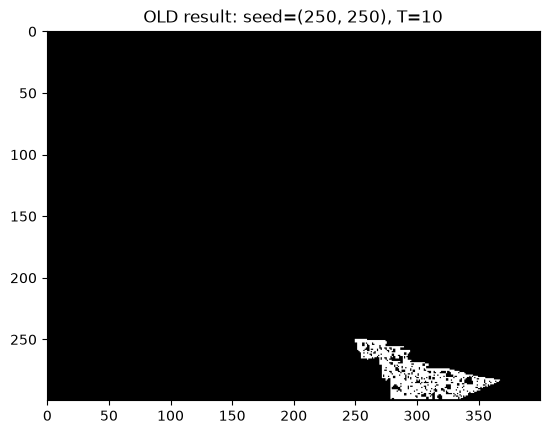

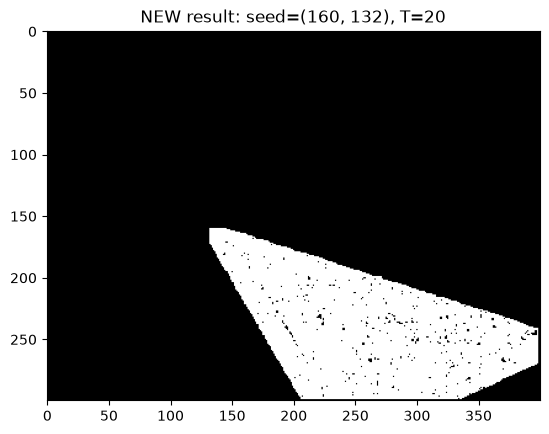

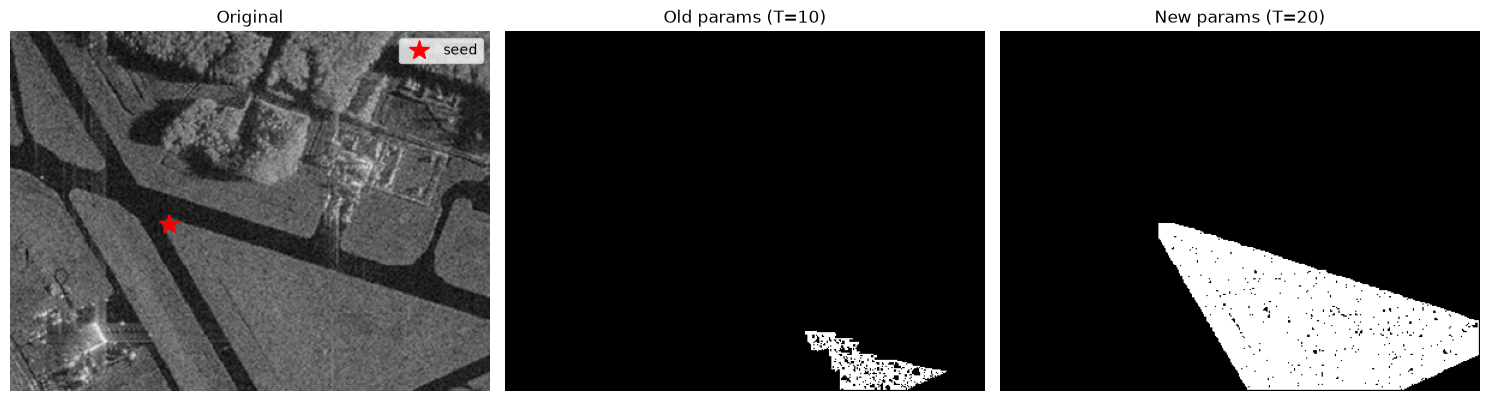

In [2]:
image = cv2.imread('source/sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

showpic(image_gray, "Original")

seed_old = (250, 250)
T_old = 10

mask_old = region_growing(image_gray, seed_old, homo_average, 1, T_old)
showpic(mask_old, f"OLD result: seed={seed_old}, T={T_old}")

seed_new = (160, 132)
T_new = 20

mask_new = region_growing(image_gray, seed_new, homo_average, 1, T_new)
showpic(mask_new, f"NEW result: seed={seed_new}, T={T_new}")

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Original')
plt.plot(seed_new[1], seed_new[0], 'r*', markersize=15, label='seed')
plt.legend()
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_old, cmap='gray')
plt.title(f'Old params (T={T_old})')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(mask_new, cmap='gray')
plt.title(f'New params (T={T_new})')
plt.axis('off')
plt.tight_layout()
plt.show()

# Задание 2

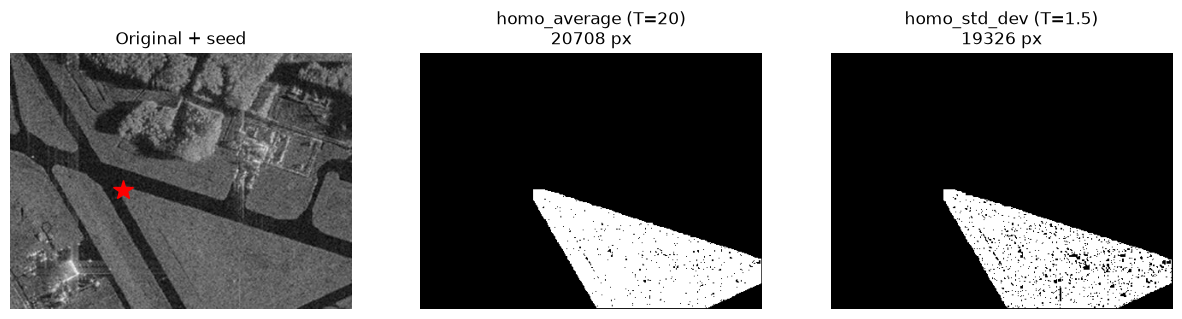

In [3]:
seed_cmp = (160, 132)

mask_avg = region_growing(image_gray, seed_cmp, homo_average, 1, 20)
mask_std = region_growing(image_gray, seed_cmp, homo_std_dev, 1, 1.5)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_gray, cmap='gray')
plt.plot(seed_cmp[1], seed_cmp[0], 'r*', markersize=15)
plt.title('Original + seed')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_avg, cmap='gray')
plt.title(f'homo_average (T=20)\n{np.count_nonzero(mask_avg)} px')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(mask_std, cmap='gray')
plt.title(f'homo_std_dev (T=1.5)\n{np.count_nonzero(mask_std)} px')
plt.axis('off')
plt.show()

# Задание 3

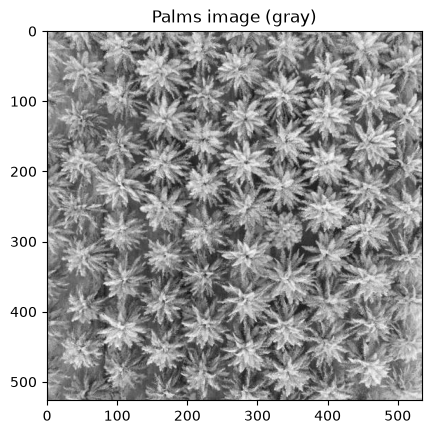

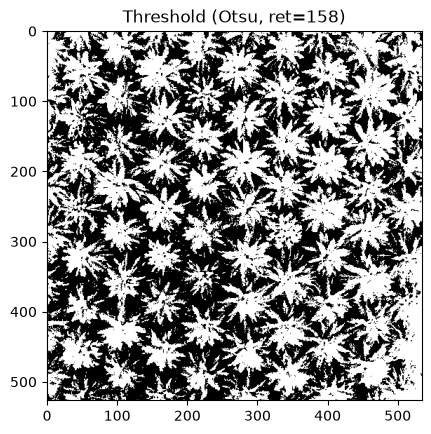

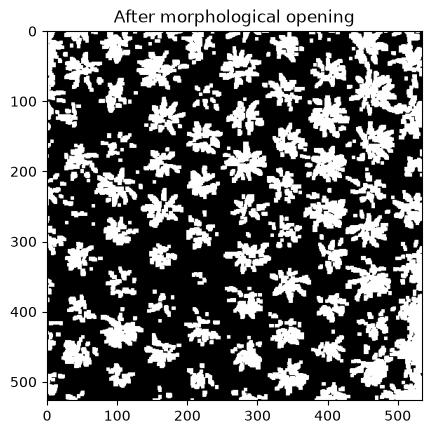

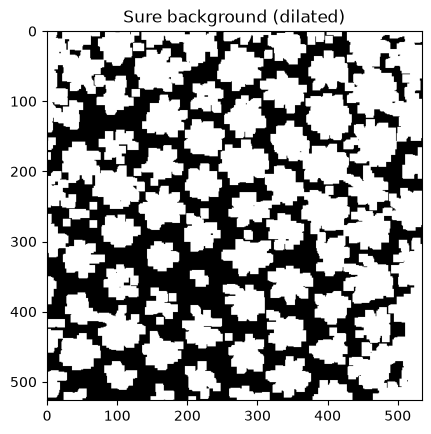

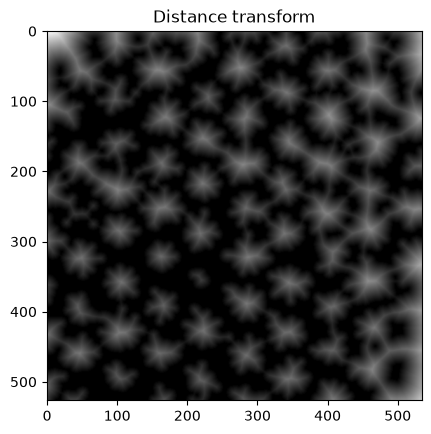

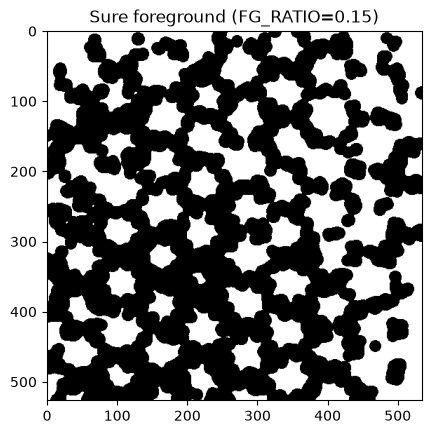

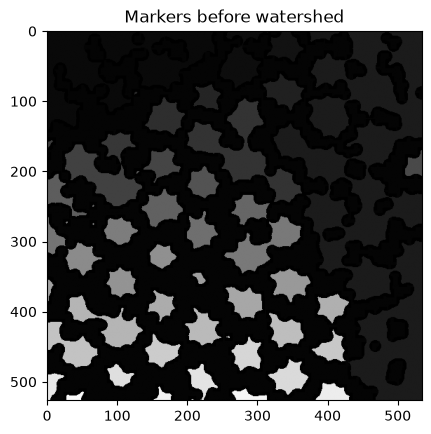

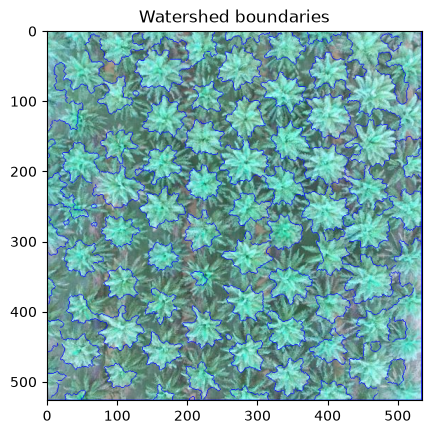

Found palms: 54


In [4]:
palms = cv2.imread('source/palm_1.jpg')
palms_gray = cv2.cvtColor(palms, cv2.COLOR_BGR2GRAY)

showpic(palms_gray, 'Palms image (gray)')

ret, thresh = cv2.threshold(
    palms_gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

showpic(thresh, f'Threshold (Otsu, ret={ret:.0f})')

kernel = np.ones((3, 3), np.uint8)

opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

sure_bg = cv2.dilate(opening, kernel, iterations=3)

showpic(opening, 'After morphological opening')
showpic(sure_bg, 'Sure background (dilated)')

opening_blur = cv2.GaussianBlur(opening, (15, 15), 0)

dist = cv2.distanceTransform(opening_blur, cv2.DIST_L2, 5)

showpic(dist, 'Distance transform')

FG_RATIO = 0.15

ret, sure_fg = cv2.threshold(dist, FG_RATIO * dist.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

showpic(sure_fg, f'Sure foreground (FG_RATIO={FG_RATIO})')

unknown = cv2.subtract(sure_bg, sure_fg)

ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

showpic(markers, 'Markers before watershed')

markers = cv2.watershed(palms, markers)

palms_vis = palms.copy()
palms_vis[markers == -1] = [0, 0, 255]

showpic(palms_vis, 'Watershed boundaries')

labels = [l for l in np.unique(markers) if l not in (-1, 0, 1)]
num_trees = len(labels)

print(f"Found palms: {num_trees}")